# Screening and Ranking Emerging Markets for Mergers & Acquisitions (M&A) Targeting Using Macroeconomic Indicators

**ADS-505: Applied Data Science for Business** | University of San Diego<br>
**Team 12:** Jordyn Gonzales, Dana Neuman, James Shoenhair<br>
**Repository:** [github.com/JamesShoenhair/ADS505_Team_12](https://github.com/JamesShoenhair/ADS505_Team_12)<br>
**Date:** October 2026

## Setup

In [1]:
# Libraries
import warnings

# Data handling
import numpy as np
import pandas as pd

# Visualiztion
import matplotlib.pyplot as plt
import seaborn as sns

# Pre-processing
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Tuning
from sklearn.model_selection import ParameterGrid

# statistics
from scipy.stats import spearmanr

# Evaluation
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    precision_score,
    roc_auc_score)

In [2]:
# Global settings
SEED = 1

# Display 
pd.set_option('display.float_format', '{:,.3f}'.format)

# Plot style
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)

## Problem Statement   
  
Corporate development and M&A teams routinely need to decide which emerging-market countries are currently the most attractive acquisition targets from a macroeconomic standpoint. Today that screening is largely manual: analysts lean on news coverage, prior deal experience, and country-by-country research, which is slow, inconsistent across analysts, and easy to bias toward markets that are already on the team's radar.   
  
**Goal:** build a transparent, repeatable model that screens and ranks emerging-market countries by their likelihood of outperforming on economic growth over the next three years, using seven IMF World Economic Outlook (WEO) indicators:   
  
1. GDP growth (constant prices, % change)
2. GDP current prices (PPP, international \$)
3. GDP per capita (PPP, international \$)
4. GDP price deflator (index)
5. General government net debt (% of GDP)
6. General government net lending/borrowing (% of GDP)
7. Current account balance (% of GDP)  
  
The output is a ranked shortlist of countries plus visibility into which indicators drive each country's ranking, so the reasoning is transparent rather than a black box, and the analysis can be re-run each time the IMF releases a new WEO vintage. 

**Prediction Target:** A binary variable equal to 1 if a country's average annual real GDP growth (year-over-year % change) over the three years after the indicator year ranks in the top 33% of emerging markets that year, and 0 otherwise. The model's predicted probability of a 1 is used to produce the ranked shortlist.

## Data Description  
  
**Source:** IMF World Economic Outlook (WEO) database, April 2026 vintage.  
**File:** `ads505final.csv`[github.com/JamesShoenhair/ADS505_Team_12](https://github.com/JamesShoenhair/ADS505_Team_12)
  
**Raw Shape:** 1,288 rows x 22 columns   
  
- DATASET: IMF source dataset identifier 
- SERIES_CODE: IMF's internal code for this series
- OBS_MEASURE: Type of value the row holds
- COUNTRY: Country or entity name
- INDICATOR: Full-text name of the macroeconomic indicator being reported
- FREQUENCY: Reporting Frequency
- SCALE: Unit scale of the value columns
- 2017, 2018, ..., 2031: One column per year from 2017–2031. 2017–2025 are actuals/estimates, 2026–2031 are IMF projections. The value in each cell is that country's reading for the row's INDICATOR, in the unit given by SCALE.

## Data Loading

In [3]:
# Load in dataset
df = pd.read_csv('ads505final.csv')

## Exploratory Data Analysis

**Data Overview**

In [4]:
print(f"Shape: {df.shape}")
df.head()

Shape: (1288, 22)


,DATASET,SERIES_CODE,OBS_MEASURE,COUNTRY,INDICATOR,FREQUENCY,SCALE,2017,2018,2019,...,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031
0,IMF.RES:WEO(9.0.0),USA.NGDP_D.A,OBS_VALUE,United States,"Gross domestic product (GDP), Price deflator, ...",Annual,Units,100.000,102.291,103.979,...,118.023,122.390,125.428,128.986,132.681,135.595,137.821,140.271,142.849,145.428
1,IMF.RES:WEO(9.0.0),GBR.NGDP_D.A,OBS_VALUE,United Kingdom,"Gross domestic product (GDP), Price deflator, ...",Annual,Units,80.664,82.247,84.271,...,94.034,100.000,103.902,107.758,110.410,112.748,115.000,117.015,119.123,121.212
2,IMF.RES:WEO(9.0.0),G110.NGDP_RPCH.A,OBS_VALUE,Advanced Economies,"Gross domestic product (GDP), Constant prices,...",Annual,Units,2.609,2.312,1.859,...,3.055,1.702,1.839,1.935,1.777,1.700,1.747,1.613,1.537,1.513
3,IMF.RES:WEO(9.0.0),LKA.GGXCNL_NGDP.A,OBS_VALUE,Sri Lanka,"Net lending (+) / net borrowing (-), General g...",Annual,Units,-5.098,-4.956,-7.519,...,-10.223,-8.323,-5.426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IMF.RES:WEO(9.0.0),GBR.BCA_NGDPD.A,OBS_VALUE,United Kingdom,"Current account balance (credit less debit), P...",Annual,Units,-3.379,-3.723,-2.479,...,-1.916,-3.570,-2.978,-3.126,-3.381,-3.144,-2.868,-2.565,-2.167,-2.218


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1288 entries, 0 to 1287
Data columns (total 22 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATASET      1288 non-null   str    
 1   SERIES_CODE  1288 non-null   str    
 2   OBS_MEASURE  1288 non-null   str    
 3   COUNTRY      1288 non-null   str    
 4   INDICATOR    1288 non-null   str    
 5   FREQUENCY    1288 non-null   str    
 6   SCALE        1288 non-null   str    
 7   2017         1286 non-null   float64
 8   2018         1287 non-null   float64
 9   2019         1288 non-null   float64
 10  2020         1282 non-null   float64
 11  2021         1282 non-null   float64
 12  2022         1282 non-null   float64
 13  2023         1282 non-null   float64
 14  2024         1282 non-null   float64
 15  2025         1269 non-null   float64
 16  2026         1254 non-null   float64
 17  2027         1247 non-null   float64
 18  2028         1242 non-null   float64
 19  2029         1242

In [6]:
df.nunique()

DATASET           1
SERIES_CODE    1288
OBS_MEASURE       1
COUNTRY         200
INDICATOR         7
FREQUENCY         1
SCALE             2
2017           1270
2018           1257
2019           1261
2020           1252
2021           1259
2022           1270
2023           1265
2024           1263
2025           1257
2026           1234
2027           1227
2028           1219
2029           1210
2030           1213
2031           1205
dtype: int64

**Data Cleaning and Reshaping**

In [7]:
# Clean up COUNTRY so that they are only an ISO-3 country/entity code
df['ISO_CODE'] = df['SERIES_CODE'].str.split('.').str[0]

# There are a couple aggregate groupings that we need to handle
aggregate_names = df.loc[df['ISO_CODE'].str.len() != 3, 'COUNTRY'].unique().tolist()
print('Non-country aggregates found in the data:')
for a in aggregate_names:
    print('-', a)

Non-country aggregates found in the data:
- Advanced Economies
- G7
- Other Advanced Economies (Advanced Economies excluding G7 and Euro Area countries)
- Euro Area (EA)


In [8]:
# We will drop the aggregates because we only want individual countries as candidate targets
data = df[~df['COUNTRY'].isin(aggregate_names)].copy()
print(f"Rows: {len(df)} -> {len(data)} after removing aggregates")
print(f"Unique countries: {data['COUNTRY'].nunique()}")

Rows: 1288 -> 1263 after removing aggregates
Unique countries: 196


Four entries are regional groupings rather than individual countries. They are identified by their IMF codes, which are not standard three-letter country codes. These are removed because the model ranks individual countries, and the groupings would double-count countries already in the data.

In [9]:
data['INDICATOR'].unique()

<StringArray>
[                                                                       'Gross domestic product (GDP), Price deflator, Index',
                                                    'Net lending (+) / net borrowing (-), General government, Percent of GDP',
                                                                'Current account balance (credit less debit), Percent of GDP',
                                                              'Gross domestic product (GDP), Constant prices, Percent change',
 'Gross domestic product (GDP), Current prices, Purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021',
     'Gross domestic product (GDP), Per capita, purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021',
                                                                               'Net debt, General government, Percent of GDP']
Length: 7, dtype: str

In [10]:
# Since INDICATOR values are long, we will map them to shorter, code-friendly names
INDICATOR_MAP  = {
    'Gross domestic product (GDP), Price deflator, Index': 'gdp_deflator_idx',
    'Net lending (+) / net borrowing (-), General government, Percent of GDP': 'net_lending_pct_gdp',
    'Current account balance (credit less debit), Percent of GDP': 'current_account_pct_gdp',
    'Gross domestic product (GDP), Constant prices, Percent change': 'gdp_growth_pct',
    'Gross domestic product (GDP), Current prices, Purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021': 'gdp_ppp_bn',
    'Gross domestic product (GDP), Per capita, purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021': 'gdp_per_capita_ppp',
    'Net debt, General government, Percent of GDP':'net_debt_pct_gdp'}
data['indicator'] = data['INDICATOR'].map(INDICATOR_MAP)

In [11]:
# reshape from dataset from wide to long (make it one row per country-indicator-year)
YEAR_COLS = [str(y) for y in range(2017, 2032)]
df_long = data.melt( id_vars=['COUNTRY', 'ISO_CODE', 'indicator'], 
                    value_vars = YEAR_COLS, var_name='year', value_name='value')
df_long['year'] = df_long['year'].astype(int)

In [12]:
all_countries = sorted(data['COUNTRY'].unique())
all_indicators = sorted(INDICATOR_MAP.values())
full_index = pd.MultiIndex.from_product(
    [all_countries, all_indicators, range(2017, 2032)],
    names=['COUNTRY', 'indicator', 'year']
)
df_long = (df_long.set_index(['COUNTRY', 'indicator', 'year'])
                    .reindex(full_index)
                    .reset_index())
print(f"Complete grid: {len(df_long)} rows "
      f"({len(all_countries)} countries x {len(all_indicators)} indicators x 15 years)")
df_long.head()

Complete grid: 20580 rows (196 countries x 7 indicators x 15 years)


,COUNTRY,indicator,year,ISO_CODE,value
0,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2017,AFG,7.576
1,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2018,AFG,12.143
2,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2019,AFG,11.705
3,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2020,AFG,13.974
4,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2021,AFG,-0.056


A country that doesn't report a given indicator at all has no row for that (country, indicator) pair, rather than a row full of `NaN`. By only looking at the rows that exist, we will systematically undercount missingness. To fix this we re-index onto the complete grid of every country × every indicator × every year. Any country–indicator pair that was absent from the raw file now appears as `NaN`, so it can be measured in the missingness analysis.

**Missing Values**

In [13]:
# to learn more about the type of missingness so we know how to handle it later
missing1 = df_long.groupby('indicator')['value'].apply(lambda s: s.isna().mean()*100).round(1)
missing2 = df_long.groupby('indicator').apply(lambda g: g.groupby('COUNTRY')['value'].apply(lambda s: s.isna().all()).sum())
missing_summary = pd.DataFrame({'% of country-years missing': missing1, 'countries with no data at all': missing2
                               }).sort_values('% of country-years missing', ascending = False)
missing_summary

,% of country-years missing,countries with no data at all
indicator,,
net_debt_pct_gdp,55.700,108
current_account_pct_gdp,2.200,1
net_lending_pct_gdp,1.900,0
gdp_growth_pct,1.600,0
gdp_deflator_idx,1.600,0
gdp_ppp_bn,1.600,0
gdp_per_capita_ppp,1.600,0


This table shows that six of the seven indicators only have about 1-2% missing values, which are likely from small or newly-independent countries. The only indicator with a substantial amount of missing values is `net_debt_pct_gdp` (55.7% missing, with 108 countries reporting none at all). This is a structural gap from smaller/lower-income economies that don't publish the underlying government balance-sheet data. (missing values will be handled in pre-processing).

**Distributions and Outliers**

To look at the distributions and outliers, we will use 2025 for a cross-sectional look. We chose 2025 because it is the most recent year of actual/estimated data and the year the model is applied to for the 2026–2028 forecast. Using this single-year snapshot will give us a fixed, representative view for understanding each indicator’s shape, outliers, and relationships.

In [14]:
snapshot2025 = (df_long[df_long['year'] == 2025].pivot(index='COUNTRY', columns='indicator', values='value'))
snapshot2025.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
indicator,,,,,,,,
current_account_pct_gdp,192.000,-1.700,10.600,-53.300,-5.600,-1.900,3.200,35.700
gdp_deflator_idx,193.000,"44,142,700,547,322.797","613,249,994,803,224.125",83.800,120.500,137.000,191.600,"8,519,541,204,340,906.000"
gdp_growth_pct,192.000,3.700,4.200,-6.400,1.800,3.100,4.900,46.100
gdp_per_capita_ppp,193.000,"32,853.400","33,914.100",994.200,"7,985.200","20,777.500","49,491.700","192,419.900"
gdp_ppp_bn,193.000,"1,087.700","4,011.800",0.100,34.900,123.400,626.700,"41,242.000"
net_debt_pct_gdp,88.000,46.000,36.500,-160.200,27.600,44.300,63.500,136.500
net_lending_pct_gdp,193.000,-2.900,6.400,-48.000,-4.800,-2.800,-1.000,31.600


Three patterns stand out. First, `gdp_deflator_idx` is unusable as a level, its mean (about 44 trillion) and maximum (about 8.5 quadrillion) are far above its median of 137, and each country's index uses a different base year, so levels aren't comparable across countries. It will be converted to year-over-year inflation. Second, `gdp_ppp_bn` and `gdp_per_capita_ppp` are heavily right-skewed, with means far above their medians, so both will be log-transformed. Third, `gdp_growth_pct` has a median of 3.1% but a maximum of 46.1%, and the remaining indicators show similar extreme tails; these will be capped (winsorized) using cutoffs set on the training years. The low count for `net_debt_pct_gdp` (88 of 193) confirms the missingness found above.

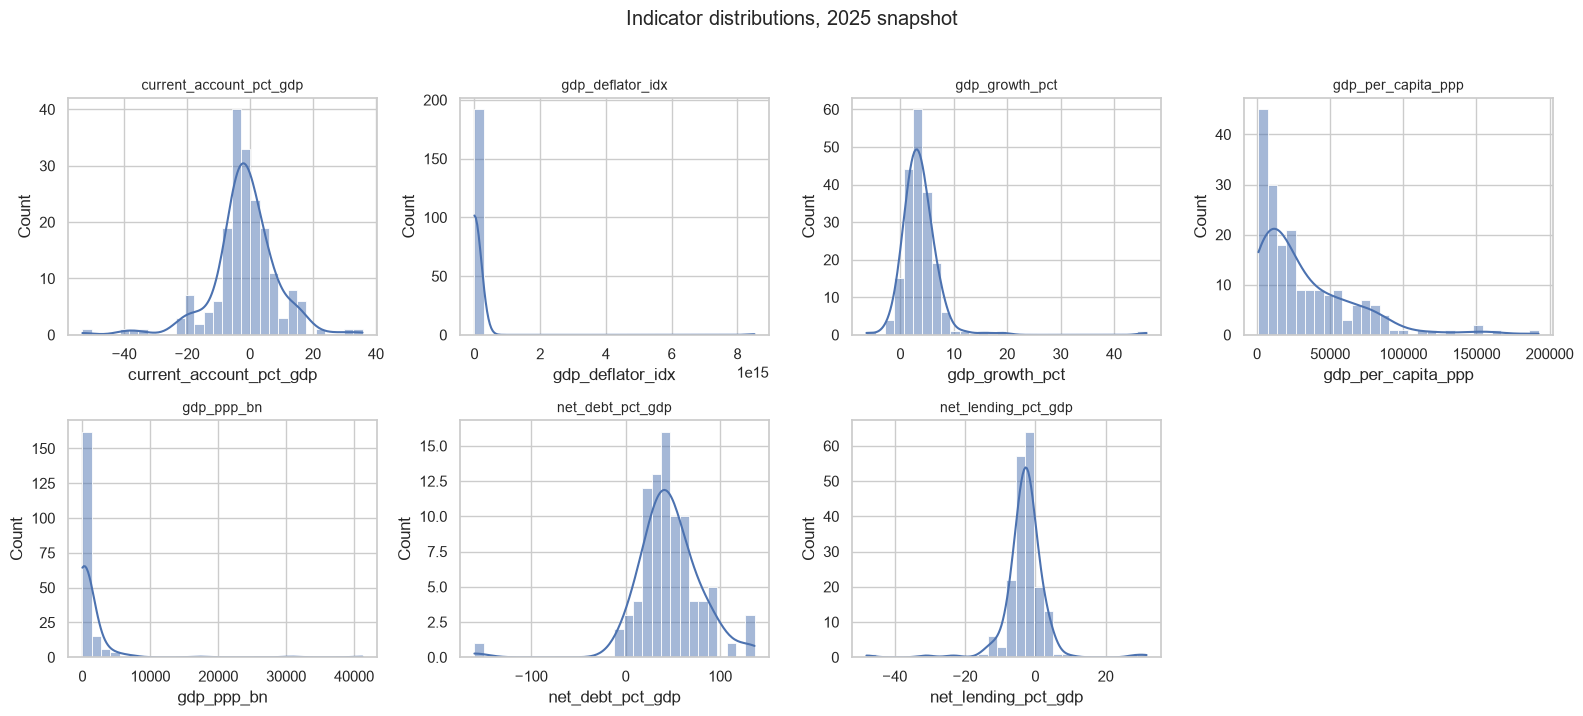

In [15]:
# Histogram of each indicator to check shape and skew
fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, col in zip(axes.flat, snapshot2025.columns):
    sns.histplot(snapshot2025[col].dropna(), ax=ax, kde=True, bins=30)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.suptitle('Indicator distributions, 2025 snapshot', y=1.02)
plt.tight_layout()
plt.show()

The histograms confirm the patterns in the summary table visually. `gdp_deflator_idx` collapses into a single bar because one extreme value stretches the axis. `gdp_ppp_bn` and `gdp_per_capita_ppp` pile up on the left with long tails to the right.`gdp_growth_pct`, `current_account_pct_gdp`, and `net_lending_pct_gdp` are roughly bell-shaped but have a few countries far out in the tails. `net_debt_pct_gdp` has a reasonable shape, but it is based on fewer than half the countries.

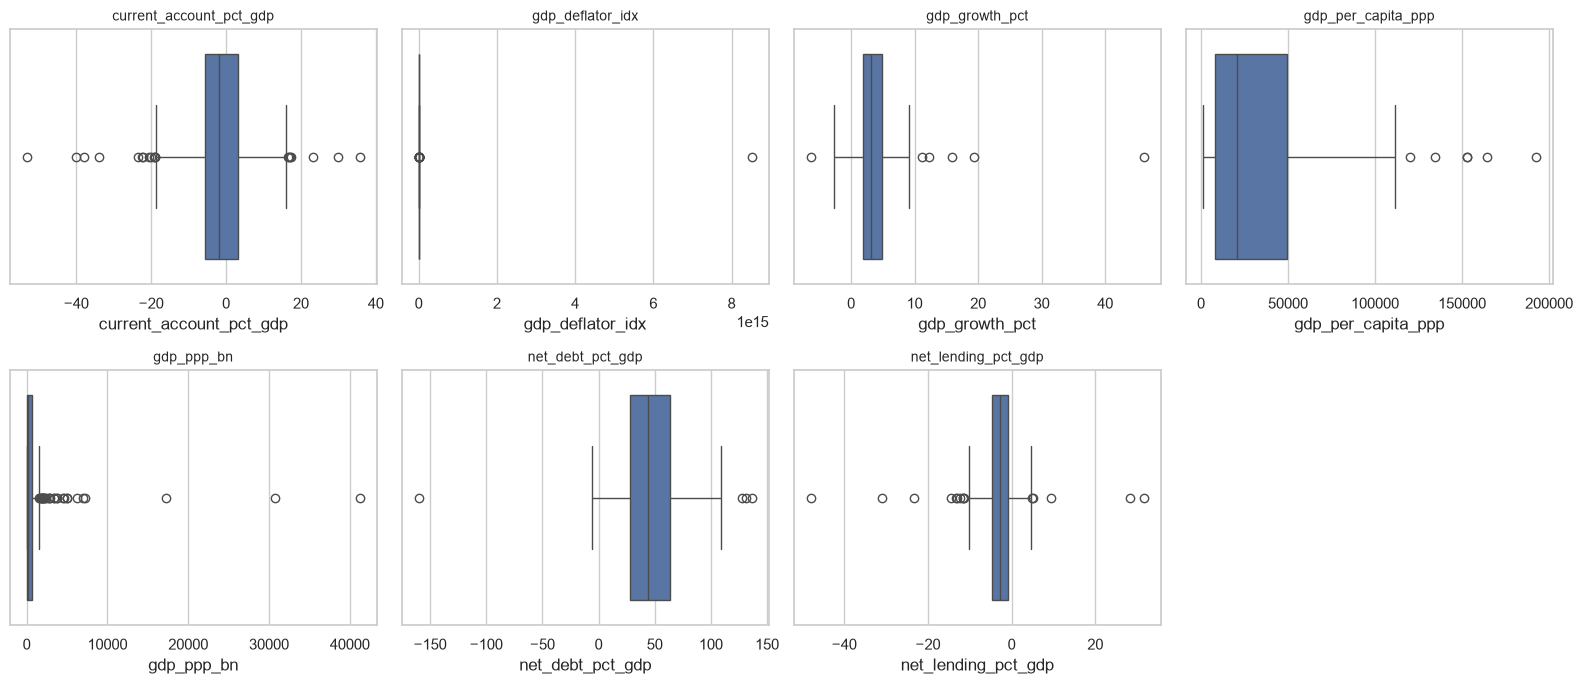

In [16]:
# Box plots to identify outliers in each indicator
fig, axes = plt.subplots(2,4, figsize = (16,7))
for ax, col in zip(axes.flat, snapshot2025.columns):
    sns.boxplot(x=snapshot2025[col].dropna(), ax=ax)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

Current account and net lending have outliers on both sides, growth and per-capita GDP mostly on the high side, and total GDP has a handful of very large economies far to the right. Net debt has a single extreme negative value, a country whose government assets far exceed its debt.

In [17]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25,.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lo) | (s > hi)].sort_values(ascending=False)

# Check which countries drive the extreme deflator values
print('Top outliers, GDP price deflator index (2025):')
print(iqr_outliers(snapshot2025['gdp_deflator_idx']).head(5))

Top outliers, GDP price deflator index (2025):
COUNTRY
Venezuela, República Bolivariana de   8,519,541,204,340,906.000
Sudan                                               941,668.049
South Sudan, Republic of                            149,939.257
Argentina                                           114,689.822
Tajikistan, Republic of                              37,567.127
Name: gdp_deflator_idx, dtype: float64


These outlier countries are a direct reflection of real high inflation (and, in some cases, older index base years), not a data-entry error. Because a price-level index compounds year after year once hyperinflation sets in, this variable needs to be converted to year-over-year inflation instead of just capping it. If we were to cap it, the distribution would be unusable since almost the entire non-outlier population would be squeezed into a sliver of the scale. The other 6 indicators have a small number of legitimate extreme outliers.

**GDP Growth Over Time**

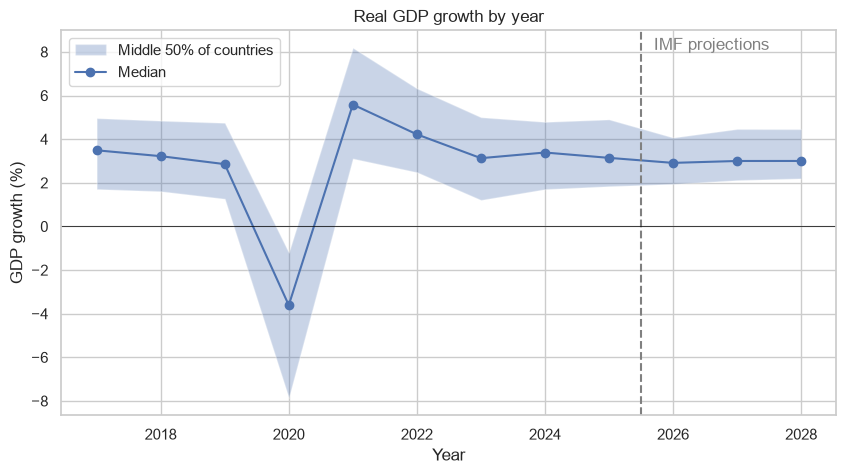

In [18]:
# Median GDP growth by year, with the middle 50% of countries shaded
growth = df_long[
    (df_long['indicator'] == 'gdp_growth_pct')
    & (df_long['year'] <= 2028)
]
by_year = growth.groupby('year')['value'].quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(by_year.index, by_year[0.25], by_year[0.75],
                alpha=0.3, label='Middle 50% of countries')
ax.plot(by_year.index, by_year[0.5], marker='o', label='Median')
ax.axvline(2025.5, color='gray', linestyle='--')
ax.text(2025.7, ax.get_ylim()[1] * 0.9, 'IMF projections', color='gray')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Real GDP growth by year')
ax.set_xlabel('Year')
ax.set_ylabel('GDP growth (%)')
ax.legend()
plt.show()

Median growth held steady at about 3% from 2017 to 2019, then fell to roughly −3.6% in 2020 as COVID-19 hit nearly every country at once, before rebounding to about 5.6% in 2021 and returning to its pre-pandemic level by 2023. The shaded band also widens sharply in 2020 and 2021, showing that countries were affected very differently. Because the whole world moved together, the target ranks countries within each year (top 33% that year) rather than using a fixed growth cutoff. Finally, the IMF projections for 2026–2028 are much smoother than any actual year.

**Correlations**

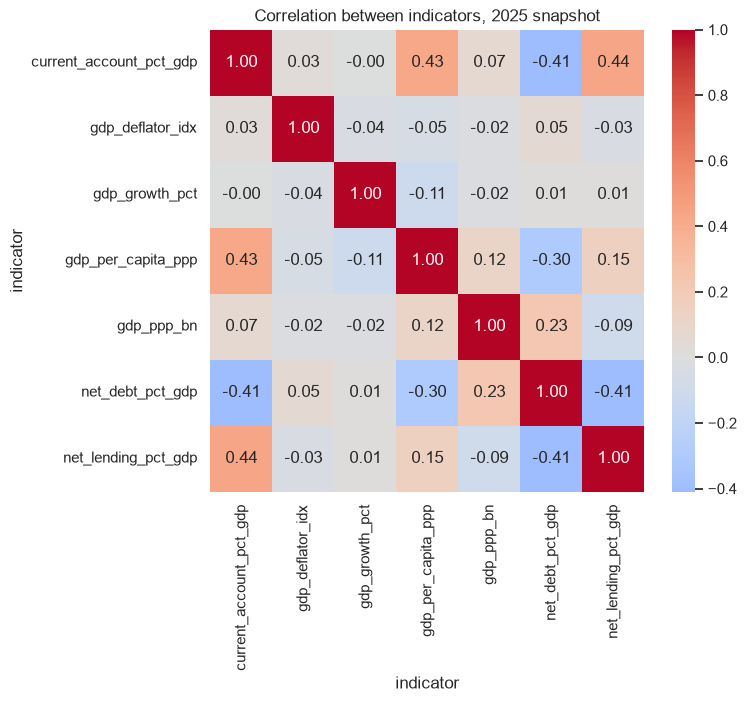

In [19]:
# check correlation between indicators
corr = snapshot2025.corr()
fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap ='coolwarm', center=0, ax=ax)
ax.set_title('Correlation between indicators, 2025 snapshot')
plt.show()

Correlations among the indicators are generally weak to moderate. The strongest relationships are domain intuitive (like net lending/borrowing correlates positively with the current account balance, at 0.44). No pair exceeds 0.7, so all indicators are kept and none need to be removed for redundancy. Correlations involving gdp_deflator_idx and gdp_ppp_bn should be read with caution, since their extreme values distort this measure; these are rechecked after transformation in pre-processing.

## Data Pre-Processing

**Dropping Net Debt**

In [20]:
# Drop net debt: missing for over half of country-years (see EDA)
df_long = df_long[df_long['indicator'] != 'net_debt_pct_gdp']

**Emerging-Market Filter and Reshaping**

In [21]:
# IMF advanced economies (WEO classification); all other countries are
# treated as emerging market and developing economies
ADVANCED_ECONOMIES = [
    'AND', 'AUS', 'AUT', 'BEL', 'CAN', 'CHE', 'CYP', 'CZE', 'DEU', 'DNK',
    'ESP', 'EST', 'FIN', 'FRA', 'GBR', 'GRC', 'HKG', 'HRV', 'IRL', 'ISL',
    'ISR', 'ITA', 'JPN', 'KOR', 'LTU', 'LUX', 'LVA', 'MAC', 'MLT', 'NLD',
    'NOR', 'NZL', 'PRI', 'PRT', 'SGP', 'SMR', 'SVK', 'SVN', 'SWE', 'TWN',
    'USA',
]

# Refill ISO codes (rows added by the full grid have none)
iso_lookup = data.drop_duplicates('COUNTRY').set_index('COUNTRY')['ISO_CODE']
df_long['ISO_CODE'] = df_long['COUNTRY'].map(iso_lookup)

# Catch any advanced-economy codes that don't match the data
missing_codes = set(ADVANCED_ECONOMIES) - set(iso_lookup)
print(f"Advanced-economy codes not found: {missing_codes or 'none'}")

# Keep emerging and developing economies only
em_long = df_long[~df_long['ISO_CODE'].isin(ADVANCED_ECONOMIES)]

# Reshape to one row per country per year, one column per indicator
panel = (
    em_long
    .pivot(index=['COUNTRY', 'year'], columns='indicator', values='value')
    .reset_index())
panel.columns.name = None

print(f"Countries: {panel['COUNTRY'].nunique()}")
print(f"Shape: {panel.shape}")
panel.head()

Advanced-economy codes not found: none
Countries: 155
Shape: (2325, 8)


,COUNTRY,year,current_account_pct_gdp,gdp_deflator_idx,gdp_growth_pct,gdp_per_capita_ppp,gdp_ppp_bn,net_lending_pct_gdp
0,"Afghanistan, Islamic Republic of",2017,7.576,102.404,2.647,"2,338.779",83.362,-0.673
1,"Afghanistan, Islamic Republic of",2018,12.143,104.525,1.189,"2,436.006",89.369,1.634
2,"Afghanistan, Islamic Republic of",2019,11.705,111.341,3.912,"2,589.410",97.801,-1.058
3,"Afghanistan, Islamic Republic of",2020,13.974,120.050,-2.351,"2,588.961",100.898,-2.243
4,"Afghanistan, Islamic Republic of",2021,-0.056,113.594,-14.542,"2,138.870",85.768,-0.485


The model ranks emerging markets only, so the 41 economies the IMF classifies as advanced are removed, leaving 155 emerging market and developing economies. The data is then reshaped so each row is one country in one year, with one column per indicator, which is the format the model needs to learn from.

**Feature Engineering**

In [22]:
# Sort so each country's years are in order before year-to-year comparisons
panel = panel.sort_values(['COUNTRY', 'year']).reset_index(drop=True)

# Inflation: year-over-year % change in the GDP deflator
panel['inflation_pct'] = (
    panel.groupby('COUNTRY')['gdp_deflator_idx'].pct_change() * 100)

# Log of GDP size and GDP per capita to reduce right skew
panel['log_gdp_ppp'] = np.log10(panel['gdp_ppp_bn'])
panel['log_gdp_per_capita'] = np.log10(panel['gdp_per_capita_ppp'])

# Growth momentum: change in growth from the prior year
panel['growth_change'] = panel.groupby('COUNTRY')['gdp_growth_pct'].diff()

# Growth relative to the typical emerging market that year
panel['growth_vs_median'] = (
    panel['gdp_growth_pct']
    - panel.groupby('year')['gdp_growth_pct'].transform('median'))

# Drop the raw columns replaced by engineered versions
panel = panel.drop(columns=['gdp_deflator_idx', 'gdp_ppp_bn', 'gdp_per_capita_ppp'])

print(f"Shape: {panel.shape}")
panel.head()

Shape: (2325, 10)


,COUNTRY,year,current_account_pct_gdp,gdp_growth_pct,net_lending_pct_gdp,inflation_pct,log_gdp_ppp,log_gdp_per_capita,growth_change,growth_vs_median
0,"Afghanistan, Islamic Republic of",2017,7.576,2.647,-0.673,NaN,1.921,3.369,NaN,-1.169
1,"Afghanistan, Islamic Republic of",2018,12.143,1.189,1.634,2.071,1.951,3.387,-1.458,-2.294
2,"Afghanistan, Islamic Republic of",2019,11.705,3.912,-1.058,6.521,1.990,3.413,2.723,0.712
3,"Afghanistan, Islamic Republic of",2020,13.974,-2.351,-2.243,7.822,2.004,3.413,-6.263,1.227
4,"Afghanistan, Islamic Republic of",2021,-0.056,-14.542,-0.485,-5.378,1.933,3.330,-12.191,-19.585


**Building the Target**

In [23]:
# Average real GDP growth over the next 3 years for each country
growth = panel.groupby('COUNTRY')['gdp_growth_pct']
panel['future_growth'] = (
    growth.shift(-1) + growth.shift(-2) + growth.shift(-3)
) / 3

# Rank each country within its year; top 33% = 1, rest = 0
pct_rank = panel.groupby('year')['future_growth'].rank(pct=True)
panel['target'] = np.where(pct_rank.isna(), np.nan, (pct_rank > 2 / 3).astype(float))

**Handling Missing Values**

In [24]:
# Model inputs (raw growth is kept only for the baseline and the target)
FEATURES = [
    'current_account_pct_gdp', 'net_lending_pct_gdp', 'inflation_pct',
    'log_gdp_ppp', 'log_gdp_per_capita', 'growth_change', 'growth_vs_median',
]

# Base years with three full years of actual outcomes: 2018-2022
model_years = panel[panel['year'].between(2018, 2022)]
model_df = model_years.dropna(subset=FEATURES + ['target']).copy()
model_df['target'] = model_df['target'].astype(int)

# 2025 rows for the 2026-2028 forecast (no target yet)
forecast_df = panel[panel['year'] == 2025].dropna(subset=FEATURES).copy()

print(f"Model rows: {len(model_years)} -> {len(model_df)} after dropping gaps")
print(f"Forecast countries (2025): {len(forecast_df)}")
print(model_df.groupby('year')['target'].mean().round(2))

# Show which country-years were dropped for missing values
dropped = model_years[~model_years.index.isin(model_df.index)]
dropped[['COUNTRY', 'year']]

Model rows: 775 -> 767 after dropping gaps
Forecast countries (2025): 151
year
2018   0.340
2019   0.340
2020   0.340
2021   0.340
2022   0.340
Name: target, dtype: float64


,COUNTRY,year
676,"Eritrea, The State of",2018
677,"Eritrea, The State of",2019
678,"Eritrea, The State of",2020
679,"Eritrea, The State of",2021
680,"Eritrea, The State of",2022
1175,"Liechtenstein, Principality of",2022
1880,Sri Lanka,2022
2270,West Bank and Gaza,2022


2017 is excluded from the modeling set because inflation and growth momentum compare each year to the year before, and the data begins in 2017, so these features cannot be calculated for that year. Of the remaining 775 country-years (2018–2022), 8 were dropped because they were missing at least one input or the three-year outcome needed for the target. Eritrea accounts for five of these, since it lacks data across every base year and is therefore excluded from the model entirely. The other three are single-year gaps in 2022 for Liechtenstein, Sri Lanka, and West Bank and Gaza; these countries still contribute their 2018–2021 rows. Because each row stands on its own as one country in one year, a country with a missing year simply contributes fewer rows, and the remaining data is unaffected.

Filling these gaps with the average of the surrounding years was considered and rejected for two reasons. First, it would use information from a later year to describe an earlier one, letting future data leak into the model's inputs. Second, several gaps fall in the final year, where there is no later value to average with. Given that only about 1% of rows are affected, dropping them is the more reliable choice. The trade-off is that the dropped cases include economies facing conflict or data-reporting difficulties, so the model has slightly less exposure to those conditions. The same four countries (Eritrea, Liechtenstein, Sri Lanka, and West Bank and Gaza) also lack complete 2025 data and will not appear in the final 2026–2028 ranking.

After dropping, 34% of countries are labeled 1 in every year from 2018 to 2022, including the 2020 COVID year, confirming that the target holds its top-33% design regardless of global conditions.

**Handling Outliers**

In [25]:
# Outliers: cap each feature at its 1st and 99th percentiles, with cutoffs
# learned from training years only so test years never influence them
class Winsorizer(BaseEstimator, TransformerMixin):
    """Cap each column at percentiles learned during fit."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.lower)
        self.hi_ = X.quantile(self.upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.clip(self.lo_, self.hi_, axis=1)

# Preview the effect on training years (2018-2020)
train_preview = model_df[model_df['year'] <= 2020]
capped = Winsorizer().fit_transform(train_preview[FEATURES])

pd.DataFrame({
    'min_before': train_preview[FEATURES].min(),
    'min_after': capped.min(),
    'max_before': train_preview[FEATURES].max(),
    'max_after': capped.max(),})

,min_before,min_after,max_before,max_after
current_account_pct_gdp,-68.779,-37.420,59.271,24.907
net_lending_pct_gdp,-30.976,-21.024,42.809,21.307
inflation_pct,-26.296,-11.025,"225,691.513",315.047
log_gdp_ppp,-1.347,-0.984,4.414,3.966
log_gdp_per_capita,2.779,2.902,5.163,4.946
growth_change,-39.832,-23.650,38.127,7.378
growth_vs_median,-30.858,-23.180,47.058,8.056


Each feature is winsorized at its 1st and 99th percentiles, with the cutoffs calculated from the training years (2018–2020) only, so the validation and test years never influence them. Winsorization pulls values beyond the cutoffs back to the cutoff rather than removing them, so every country stays in the dataset. This matters because logistic regression and LDA rely on each feature's mean and variance: LDA estimates class means and a shared covariance, and standard scaling divides by the standard deviation. A single extreme value inflates both the mean and the standard deviation, compressing the meaningful differences among all other countries into a narrow range and letting one observation pull the model's coefficients toward itself. The table shows the effect, inflation changes the most, with a maximum of over 225,000% from hyperinflation cases capped at 315%, which keeps a handful of extreme economies from dominating the model while still marking them as high-inflation. Growth momentum and growth relative to the median are also pulled in sharply on the high side (from 38 and 47 percentage points to about 7 and 8), reflecting a few countries with one-off growth surges. The log-transformed GDP features barely change, since the log transformation had already compressed their extremes.

A reasonable concern is that capping could hide which countries are too risky because of volatile growth or extreme inflation. Winsorization preserves each country's rank order, so a capped country remains at the extreme end of that feature and is still identified as high-risk; only the magnitude of its distance from other countries is reduced. The target is also built from actual, uncapped future growth, so countries with exceptional growth are still labeled as top performers.

**Final Feature Check**

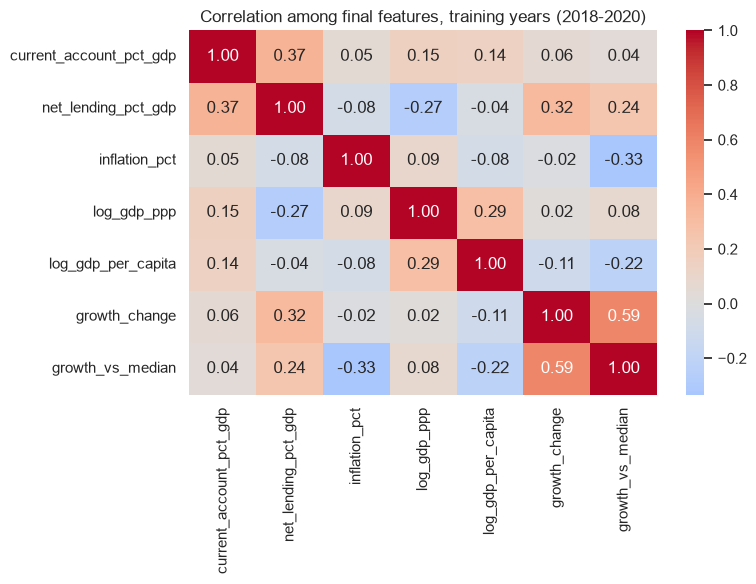

In [26]:
# Correlation among final model features (training years, after winsorizing)
corr_final = capped.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_final, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax)
ax.set_title('Correlation among final features, training years (2018-2020)')
plt.tight_layout()
plt.show()

After feature engineering and winsorization, correlations among the seven final features remain weak to moderate, and no pair exceeds 0.7, so all features are kept. The 0.7 cutoff follows Dormann et al. (2013), who found that correlations above this level begin to seriously distort model estimates. This matters most for logistic regression and LDA, whose coefficients become unstable when features overlap heavily. The strongest relationship is between growth momentum and growth relative to the median (0.59), which is expected since both are built from GDP growth, but they capture different signals, whether a country’s growth is accelerating, and whether it is outpacing other emerging markets that year. At 0.59, the two share only about a third of their information (0.59² ≈ 0.35), so each still contributes mostly distinct information. The current account and government net lending move together moderately (0.37). Inflation is negatively related to relative growth (−0.33), as high-inflation economies tend to grow more slowly than their peers. Compared with the raw-data correlations in the EDA, these relationships are now measured on transformed, comparable features, so they reflect real economic patterns rather than distortions from extreme values. Overall, the predominantly low correlations mean each feature adds distinct information, which supports stable, interpretable models.

## Data Splitting

Because each row's target depends on what happened in later years, the data is split by year rather than at random. A random split would place, for example, a 2021 row in training and a 2020 row in testing, letting the model learn from the future to predict the past. Instead, the model trains on base years 2018–2020, is tuned on 2021, and is evaluated once on 2022, mirroring how it would be used in practice, learning from the past to rank countries on years it has never seen. Base years 2023 and 2024 are not used as rows because their three-year outcome windows extend into 2026 and beyond, which are IMF projections rather than actual results; their growth data is instead used as the outcomes that label the 2020–2022 rows.

One limitation of this design is that the three-year outcome windows overlap across splits. For example, the 2020 training rows are labeled by growth in 2021–2023, while the 2021 validation rows are labeled by growth in 2022–2024, so both share outcomes from 2022 and 2023. This may make validation and test scores slightly optimistic. Fully separating the outcome windows would require excluding all training years after 2018, leaving too few rows to train on, so the overlap is accepted and disclosed rather than removed. 

Because the same countries appear in consecutive years, observations are not fully independent. The temporal split and a fixed validation year, rather than random cross-validation, keep this from leaking information between training and evaluation.

**Temporal Split Design**

In [27]:
# Temporal split by base year
train = model_df[model_df['year'] <= 2020]
val = model_df[model_df['year'] == 2021]
test = model_df[model_df['year'] == 2022]

X_train, y_train = train[FEATURES], train['target']
X_val, y_val = val[FEATURES], val['target']
X_test, y_test = test[FEATURES], test['target']

pd.DataFrame({
    'years': ['2018-2020', '2021', '2022'],
    'rows': [len(train), len(val), len(test)],
    'share_labeled_1': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['train', 'validation', 'test'])

,years,rows,share_labeled_1
train,2018-2020,462,0.338
validation,2021,154,0.338
test,2022,151,0.338


The training set contains 462 country-years from 2018–2020, the validation set 154 countries from 2021, and the test set 151 countries from 2022. Training has three rows fewer than 155 countries × 3 years because Eritrea has no usable data, and the test set is smaller because Liechtenstein, Sri Lanka, and West Bank and Gaza lack complete 2022 data. The share of countries labeled 1 is 33.8% in every split, confirming that the within-year ranking keeps the target balanced across training, validation, and test, so differences in model performance between splits reflect the model rather than a shift in class balance.

| Split | Inputs from | Answer (avg. growth over) | Rows |
|---|---|---|---|
| Train | 2018, 2019, 2020 | 2019–21, 2020–22, 2021–23 | 462 |
| Validation | 2021 | 2022–2024 | 154 |
| Test | 2022 | 2023–2025 | 151 |

Each row's inputs come from one year, and its target is based on average growth over the following three years. The table above shows which years supply the inputs and which years supply the answer for each split.

In [28]:
# Bundle winsorizing, scaling, and the model so every model gets the same
# pre-processing, learned from the training data only
def make_pipeline(model):
    return Pipeline([
        ('winsorize', Winsorizer()),
        ('scale', StandardScaler()),
        ('model', model),])

## Model Building Strategy

The modeling approach is designed to answer three research questions:

1. Do macroeconomic indicators identify future top-growth emerging markets better than recent growth alone?
2. Which indicators contribute most to identifying those markets?
3. How closely does the model's ranking for 2026–2028 agree with a ranking based on the IMF's own projections?

To answer the first question, every model is compared against a naive persistence baseline that ranks countries by their current-year growth, on the assumption that today's fastest growers remain the fastest. This mirrors the simplest screen an analyst might apply without a model, so a model that cannot outperform it adds no practical value.

Three classifiers are compared. Logistic regression provides an interpretable starting point whose coefficients show the direction and relative weight of each indicator. Linear discriminant analysis offers a different statistical approach to the same linear separation and can be stabilized with shrinkage, which helps with a small training set. A random forest captures non-linear relationships and interactions between indicators that the two linear models cannot. Each model is tuned on the 2021 validation year, the best configuration is selected, and the chosen model is evaluated once on the 2022 test year.

Models are evaluated on two metrics. ROC-AUC measures how well a model ranks actual top-growth countries above the rest across the full list, where 0.5 reflects random ranking and 1.0 a perfect ranking. Precision@10 measures the share of the model's ten highest-ranked countries that were actual top-growth markets, reflecting how the output would be used in practice: an M&A team investigates a short list of top candidates rather than every country. Accuracy is not used because, with roughly one-third of countries labeled 1, a model predicting 0 for every country would already be about 66% accurate. Because the same countries appear in consecutive years, models are judged on these predictive metrics rather than significance tests, which assume independent observations.

## Model Training and Tuning

**Baseline**

In [29]:
# Precision_at_k: share of the model's top-k countries that were actual top growers
def precision_at_k(y_true, scores, k=10):
    top_k = np.argsort(np.asarray(scores))[::-1][:k]
    return np.asarray(y_true)[top_k].mean()


# Score any model's rankings with the two project metrics
def evaluate(name, y_true, scores):
    return {
        'model': name,
        'roc_auc': roc_auc_score(y_true, scores),
        'precision_at_10': precision_at_k(y_true, scores),
    }

In [30]:
# Baseline: rank countries by this year's growth ("fast growers stay fast")
baseline_results = pd.DataFrame([
    evaluate('Baseline', y_val, val['gdp_growth_pct']),
])
baseline_results

,model,roc_auc,precision_at_10
0,Baseline,0.564,0.500


The baseline is scored on the 2021 validation year, the year reserved for comparing and tuning models, while the 2022 test year is held back for the final evaluation. It ranks countries by their 2021 real GDP growth (`gdp_growth_pct`, the year-over-year percent change in constant-price GDP) and is scored on whether they were top growers over 2022–2024. Its ROC-AUC of 0.564 is only slightly above the 0.50 expected from random ranking, indicating that a country's current growth alone is a weak signal of its growth over the next three years. This is likely amplified in 2021, when growth largely reflected rebounds from the 2020 COVID downturn rather than lasting momentum. Precision at 10 is 0.50, meaning 5 of the baseline's top 10 countries were actual top growers, compared with roughly 3 to 4 expected by chance. These scores set the bar each model must exceed to show that the macroeconomic indicators add value beyond recent growth alone.

In [31]:
# Train the model once per setting on 2018-2020, score each on 2021,
# and return all settings sorted from best to worst ROC-AUC
def tune(name, model, param_grid):
    rows = []
    for params in ParameterGrid(param_grid):
        pipe = make_pipeline(clone(model).set_params(**params))
        pipe.fit(X_train, y_train)
        scores = pipe.predict_proba(X_val)[:, 1]
        rows.append({**params, **evaluate(name, y_val, scores)})
    return pd.DataFrame(rows).sort_values('roc_auc', ascending=False)

**Logistic Regression**

In [32]:
# C: lower = simpler model; class_weight='balanced' gives the 1s more weight
lr_results = tune(
    'Logistic regression',
    LogisticRegression(max_iter=1000),
    {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']},
)
lr_results.head()

,C,class_weight,model,roc_auc,precision_at_10
1,0.010,balanced,Logistic regression,0.626,0.400
0,0.010,NaN,Logistic regression,0.625,0.400
5,1.000,balanced,Logistic regression,0.621,0.600
7,10.000,balanced,Logistic regression,0.620,0.600
4,1.000,NaN,Logistic regression,0.620,0.500


The best logistic regression uses strong regularization (C = 0.01) with balanced class weights, reaching a validation ROC-AUC of 0.626 compared with the baseline's 0.564. Scores barely change across settings (0.620–0.626), so the model is not sensitive to tuning. The strongest regularization winning suggests the signal in the indicators is modest, and a simpler model generalizes better than a flexible one on this small training set. Precision at 10 is 0.40, below the baseline's 0.50; with only ten countries, a single country changes this metric by 0.10, so ROC-AUC is used to select settings.

**Linear Discriminant Analysis**

In [33]:
# shrinkage: pulls estimates toward simpler values, which helps with small data
lda_results = tune(
    'LDA',
    LinearDiscriminantAnalysis(solver='lsqr'),
    {'shrinkage': [None, 'auto', 0.1, 0.5]},
)
lda_results.head()

,shrinkage,model,roc_auc,precision_at_10
3,0.500,LDA,0.624,0.400
1,auto,LDA,0.618,0.500
0,None,LDA,0.613,0.500
2,0.100,LDA,0.613,0.500


The best LDA uses a shrinkage of 0.5, reaching a validation ROC-AUC of 0.624, nearly identical to logistic regression. This is expected, since both are linear models that separate the classes in similar ways. As with logistic regression, the heaviest shrinkage performed best, reinforcing that simpler models suit this data. Precision at 10 is 0.40.

**Random Forest**

In [34]:
# max_depth and min_samples_leaf limit tree size to prevent overfitting
rf_results = tune(
    'Random forest',
    RandomForestClassifier(n_estimators=300, random_state=SEED),
    {
        'max_depth': [3, 5, None],
        'min_samples_leaf': [1, 5, 10],
        'class_weight': [None, 'balanced'],
    },
)
rf_results.head()

,class_weight,max_depth,min_samples_leaf,model,roc_auc,precision_at_10
11,balanced,3.000,10,Random forest,0.593,0.500
9,balanced,3.000,1,Random forest,0.592,0.500
10,balanced,3.000,5,Random forest,0.592,0.500
2,NaN,3.000,10,Random forest,0.588,0.600
1,NaN,3.000,5,Random forest,0.587,0.700


The best random forest uses shallow trees (maximum depth 3), a minimum of 10 countries per leaf, and balanced class weights, reaching a validation ROC-AUC of 0.593: above the baseline, but below both linear models. Every top setting uses the shallowest depth tested, indicating that deeper trees overfit the 462 training rows. The random forest's flexibility to capture non-linear patterns does not help here, suggesting the relationships in this data are largely linear. Its precision at 10 of 0.50 matches the baseline.

## Results

In [35]:
# Best setting from each model alongside the baseline (validation, 2021)
comparison = pd.concat([
    baseline_results,
    lr_results.head(1),
    lda_results.head(1),
    rf_results.head(1),
])[['model', 'roc_auc', 'precision_at_10']].reset_index(drop=True)
comparison

,model,roc_auc,precision_at_10
0,Baseline,0.564,0.500
1,Logistic regression,0.626,0.400
2,LDA,0.624,0.400
3,Random forest,0.593,0.500


On the 2021 validation year, all three models outperform the naive persistence baseline on ROC-AUC, indicating that the macroeconomic indicators carry some signal beyond current growth alone. The two linear models perform best and nearly identically (logistic regression 0.626, LDA 0.624), while the random forest trails (0.593), suggesting the relationships in this data are largely linear and that the added flexibility of the random forest leads to overfitting on a small training set. No model improves on the baseline's precision at 10 (0.50); however, with only ten countries in the shortlist, one country shifts this metric by 0.10, so the gains in overall ranking are treated as the more reliable signal. The improvement over the baseline is modest, consistent with the difficulty of forecasting relative growth over a three-year horizon.

## Final Model Selection
Logistic regression is selected as the final model. It achieved the highest validation ROC-AUC (0.626), effectively tied with LDA (0.624) and ahead of the random forest (0.593). Between the two linear models, logistic regression is preferred because its coefficients directly show the direction and weight of each indicator, making the ranking easier to explain to decision-makers. The selected setting uses strong regularization (C = 0.01) and balanced class weights. Before the one-time test evaluation, the model is retrained on both the training and validation years (2018–2021) so it learns from all available data prior to the test year.

In [36]:
# Final model: best logistic regression setting from tuning
final_params = {'C': 0.01, 'class_weight': 'balanced'}

# Retrain on training + validation years (2018-2021) before the one-time test
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
final_pipe = make_pipeline(LogisticRegression(max_iter=1000, **final_params))
final_pipe.fit(X_trval, y_trval)

# Score the final model and the baseline on the 2022 test year
test_scores = final_pipe.predict_proba(X_test)[:, 1]
test_results = pd.DataFrame([
    evaluate('Logistic regression', y_test, test_scores),
    evaluate('Baseline', y_test, test['gdp_growth_pct']),
])
test_results

,model,roc_auc,precision_at_10
0,Logistic regression,0.669,0.500
1,Baseline,0.715,0.600


On the 2022 test year, the final logistic regression reached a ROC-AUC of 0.669 and a precision at 10 of 0.50, while the naive persistence baseline reached 0.715 and 0.60. The baseline therefore outperforms the model on the held-out year, reversing the validation result. The reversal reflects how much the baseline depends on economic conditions: in 2021, current growth was dominated by rebounds from the 2020 downturn and was a poor guide to future growth, while by 2022 conditions had normalized and current growth became a much stronger signal. The model's performance also improved from validation to test, but by less. On this evidence, the macroeconomic indicators do not identify future top-growth emerging markets better than current growth alone, and the model was not re-tuned after seeing the test result, so that this comparison remains an unbiased estimate of real-world performance.

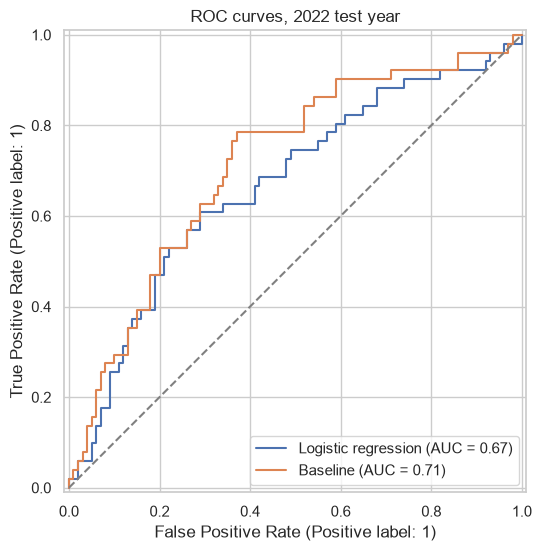

In [37]:
# ROC curves on the 2022 test year: final model vs. baseline
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, test_scores,
                                 name='Logistic regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, test['gdp_growth_pct'],
                                 name='Baseline', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_title('ROC curves, 2022 test year')
plt.show()

The ROC curves show how each method trades correctly identified top growers (true positive rate) against countries wrongly flagged (false positive rate) as the shortlist grows, with the dashed diagonal representing random ranking. Both curves sit above the diagonal, confirming each carries real signal. At the far left, where only the highest-ranked countries are selected, the two curves nearly overlap, meaning the model and the baseline perform similarly on the very top of their lists, which is the portion most relevant to an M&A shortlist. The baseline's advantage appears in the middle of the curve (false positive rates of roughly 0.3 to 0.6), where it ranks mid-tier countries more accurately, and this is the main source of its higher overall ROC-AUC (0.71 versus 0.67).

## Final Model Insights

**Indicator Importance**

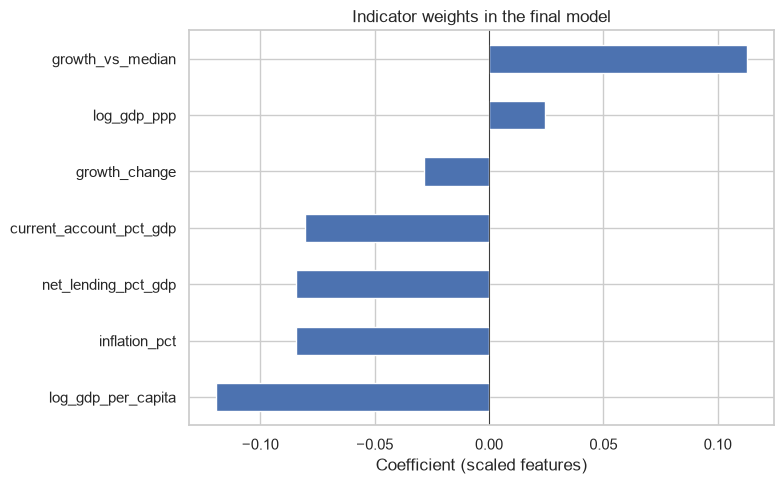

In [38]:
# Logistic regression coefficients on scaled features:
# sign = direction, size = relative strength
coefs = pd.Series(
    final_pipe.named_steps['model'].coef_[0], index=FEATURES
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
coefs.plot.barh(ax=ax)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_title('Indicator weights in the final model')
ax.set_xlabel('Coefficient (scaled features)')
plt.tight_layout()
plt.show()

Because features are scaled, coefficient size reflects each indicator's relative influence, and the sign shows its direction. The strongest signal is GDP per capita, with a negative weight: poorer emerging markets are more likely to become top growers, consistent with the economic theory of convergence, in which lower-income economies have more room to catch up. Growth relative to the median is the strongest positive signal, reflecting persistence among countries already outpacing their peers. Higher inflation lowers the likelihood of top growth, while current account and government balances carry negative weights, meaning deficits are associated with higher future growth, consistent with fast-growing emerging markets borrowing externally to fund investment. Economy size and growth acceleration contribute little. These are associations rather than causes, and because strong regularization shrinks all coefficients toward zero, the weights are best compared relative to one another rather than read as absolute effects.

**2026-2028 Forecast**

In [39]:
# Retrain the final model on all labeled years (2018-2022)
forecast_pipe = make_pipeline(LogisticRegression(max_iter=1000, **final_params))
forecast_pipe.fit(model_df[FEATURES], model_df['target'])

# Score each country's 2025 data: probability of top-33% growth in 2026-2028
forecast = forecast_df[['COUNTRY']].copy()
forecast['model_prob'] = forecast_pipe.predict_proba(forecast_df[FEATURES])[:, 1]
forecast['model_rank'] = forecast['model_prob'].rank(ascending=False).astype(int)
forecast.sort_values('model_rank').head(10)

,COUNTRY,model_prob,model_rank
1163,Libya,0.642,1
2033,"Timor-Leste, Democratic Republic of",0.631,2
8,"Afghanistan, Islamic Republic of",0.615,3
1868,"South Sudan, Republic of",0.606,4
833,Guinea,0.602,5
1493,Niger,0.594,6
1208,Malawi,0.589,7
1088,Kyrgyz Republic,0.589,8
1043,Kiribati,0.587,9
2153,Uganda,0.585,10


Retrained on all labeled years (2018–2022) and applied to 2025 data, the model's top ten candidates for 2026–2028 are dominated by low-income, small, or conflict-affected economies, including Libya, Afghanistan, South Sudan, and Niger. This follows directly from the model's strongest signal: lower GDP per capita is associated with faster future growth, so the poorest economies rank highest. While this is consistent with economic convergence, it exposes a gap between the model's target and the business goal: the model identifies countries likely to grow fastest, not countries that are investable. Many of the top-ranked markets carry sanctions, conflict, institutional, or scale risks that would exclude them from an M&A shortlist. The predicted probabilities are also tightly clustered (0.585 to 0.642), indicating the model separates countries only weakly. The ranking is therefore best used as a starting point that must be combined with risk and market-size screens before informing acquisition decisions.

**IMF Comparison**

In [40]:
# IMF ranking: average projected growth for 2026-2028
imf_growth = (
    panel[panel['year'].between(2026, 2028)]
    .groupby('COUNTRY')['gdp_growth_pct'].mean()
)
forecast['imf_growth'] = forecast['COUNTRY'].map(imf_growth)
forecast['imf_rank'] = forecast['imf_growth'].rank(ascending=False)

# Overall agreement between the two rankings (1 = identical, 0 = unrelated)
rho, _ = spearmanr(forecast['model_rank'], forecast['imf_rank'],
                   nan_policy='omit')
print(f"Rank agreement (Spearman): {rho:.2f}")

# Agreement on the top 10
model_top = set(forecast.nsmallest(10, 'model_rank')['COUNTRY'])
imf_top = set(forecast.nsmallest(10, 'imf_rank')['COUNTRY'])
print(f"\nHigh confidence (top 10 in both): {sorted(model_top & imf_top)}")
print(f"\nModel only, flag for review: {sorted(model_top - imf_top)}")
print(f"\nIMF only, flag for review: {sorted(imf_top - model_top)}")

Rank agreement (Spearman): 0.59

High confidence (top 10 in both): ['Guinea', 'Uganda']

Model only, flag for review: ['Afghanistan, Islamic Republic of', 'Kiribati', 'Kyrgyz Republic', 'Libya', 'Malawi', 'Niger', 'South Sudan, Republic of', 'Timor-Leste, Democratic Republic of']

IMF only, flag for review: ['Benin', 'Bhutan', 'Ethiopia, The Federal Democratic Republic of', 'Guyana', 'Rwanda', 'Sudan', 'Suriname', 'Vietnam']


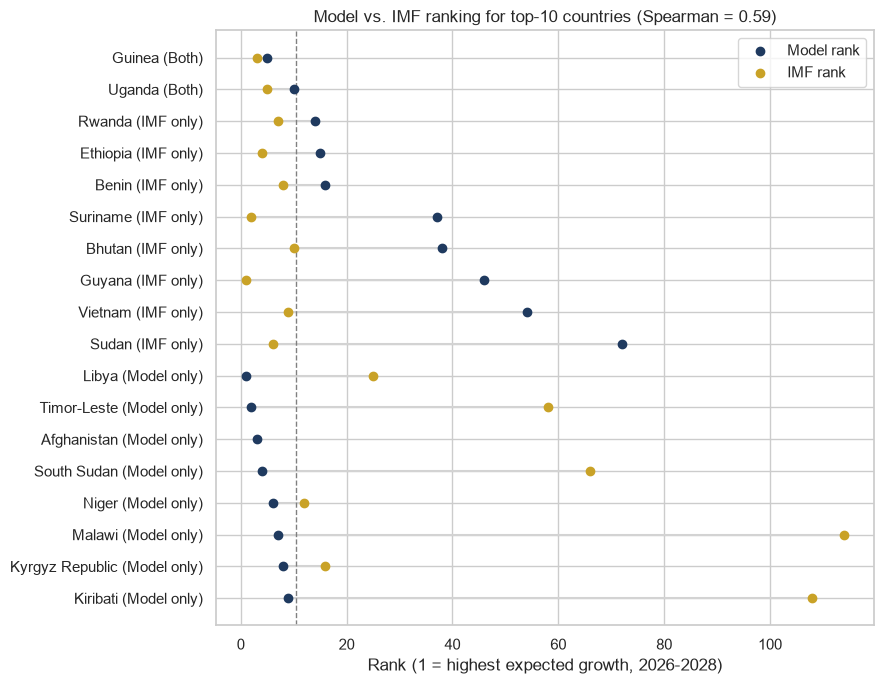

In [41]:
# Countries in either top 10, with their rank under each method
flagged = forecast[forecast['COUNTRY'].isin(model_top | imf_top)].copy()
flagged['name'] = flagged['COUNTRY'].str.split(',').str[0]
flagged['group'] = np.select(
    [flagged['COUNTRY'].isin(model_top & imf_top),
     flagged['COUNTRY'].isin(model_top)],
    ['Both', 'Model only'],
    default='IMF only',
)
flagged = flagged.sort_values(['group', 'model_rank'])

fig, ax = plt.subplots(figsize=(9, 7))
rows = range(len(flagged))
ax.hlines(rows, flagged['model_rank'], flagged['imf_rank'], color='lightgray')
ax.scatter(flagged['model_rank'], rows, color='#1F3A5F', label='Model rank', zorder=3)
ax.scatter(flagged['imf_rank'], rows, color='#C9A227', label='IMF rank', zorder=3)
ax.axvline(10.5, color='gray', linestyle='--', linewidth=1)
ax.set_yticks(list(rows))
ax.set_yticklabels(flagged['name'] + ' (' + flagged['group'] + ')')
ax.invert_yaxis()
ax.set_xlabel('Rank (1 = highest expected growth, 2026-2028)')
ax.set_title(f'Model vs. IMF ranking for top-10 countries (Spearman = {rho:.2f})')
ax.legend()
plt.tight_layout()
plt.show()

The chart shows how far apart the two rankings are for each country in either top ten, where a longer line means greater disagreement. Several apparent disagreements are near-misses: Rwanda, Ethiopia, and Benin rank just outside the model's top ten, and Niger and the Kyrgyz Republic rank just outside the IMF's, so the two methods broadly agree on a wider group of roughly seven countries. The sharpest disagreements run in both directions. The model ranks Malawi and Kiribati in its top ten while the IMF ranks them below 100th, likely because the model rewards their low income levels. Conversely, the IMF ranks Guyana, Suriname, Vietnam, and Sudan near the top while the model places them far lower, likely because their projected growth rests on country-specific drivers, such as new oil production or post-crisis recovery, that the seven indicators do not capture. These large gaps are the countries where analyst judgment is most needed.

In [42]:
# Where the BRIC countries rank under each method
# BRIC (Brazil, Russia, India, China)
bric = forecast[forecast['COUNTRY'].str.contains('Brazil|Russia|India|China')]
bric[['COUNTRY', 'model_rank', 'imf_rank']]

,COUNTRY,model_rank,imf_rank
308,Brazil,69,125.000
473,"China, People's Republic of",63,51.000
923,India,19,11.000
1703,Russian Federation,135,145.000


### Reality Check: The BRIC Economies

Brazil, Russia, India, and China were grouped as the "BRIC" economies by Goldman Sachs economist Jim O'Neill (2001), who identified them as the large emerging markets expected to drive global growth, and they remain the reference point for emerging-market investing. All four are still classified as emerging markets by the IMF. Their 2026–2028 rankings show how much that picture has changed: India ranks near the top under both methods (19th by the model, 11th by the IMF), while China (63rd and 51st), Brazil (69th and 125th), and Russia (135th and 145th) fall in the middle or bottom. The fastest expected growth has shifted toward smaller and lower-income economies. This also illustrates the limits of ranking by growth alone, China and Brazil remain far larger markets than most top-ranked countries, and for an acquirer, market size and stability can matter as much as growth rate.

## Model Brief

**To:** Data science team  
**Re:** Emerging-market growth screening model: decisions, findings, and next steps

**Purpose.** Business school still frames emerging-market opportunity around the BRIC economies, yet our forecast places only India near the top. This project asked whether IMF macroeconomic indicators can identify which emerging markets will outgrow their peers over the next three years, producing a repeatable first-pass screen for M&A targeting.

**What we tried and why.** We restructured the IMF WEO data (April 2026) into one row per country per year, 2018–2022, across 155 emerging and developing economies. The target equals 1 if a country's average real GDP growth over the following three years ranks in the top 33% of emerging markets that year. Ranking within each year, rather than using a fixed growth cutoff, keeps classes balanced (34% in every year) and neutralizes global shocks such as COVID-19. Seven features were engineered: inflation (converted from the GDP deflator, whose index levels are not comparable across countries), log GDP and log GDP per capita, current account and government balances, growth momentum, and growth relative to the median emerging market. Net debt was dropped (over half missing). Because labels look three years ahead, we split by year (train 2018–2020, validate 2021, test 2022) rather than randomly, and fit winsorization and scaling inside a pipeline on training data only. We compared logistic regression, LDA, and a random forest against a naive persistence baseline that ranks countries by current growth, judging on ROC-AUC and precision at 10.

**What each approach revealed.** On validation, all three models beat the baseline on ROC-AUC (logistic regression 0.626, LDA 0.624, random forest 0.593, baseline 0.564), and the most heavily regularized setting of each won, indicating a modest signal that simple models capture best. The random forest's lower score suggests the relationships are largely linear. On the 2022 test year, however, the baseline outperformed the selected logistic regression (ROC-AUC 0.715 vs. 0.669). The reversal reflects the baseline's sensitivity to conditions: 2021 growth was distorted by post-COVID rebounds, while 2022 growth was a cleaner signal. The model was not re-tuned after the test. Its coefficients point to convergence: lower GDP per capita is the strongest predictor of future top growth, followed by growth relative to peers, with higher inflation and stronger external and fiscal balances associated with lower odds. As a result, its 2026–2028 top ten is dominated by low-income and fragile states (Libya, Afghanistan, South Sudan). Agreement with an IMF-projection ranking is moderate (Spearman 0.59), with only Guinea and Uganda in both top tens.

**Known limitations.** The target measures growth, not investability, so the model favors poor and conflict-affected economies an acquirer would exclude. History is short: data begins in 2017, which is lost to the lagged features, leaving 462 training rows, and repeated countries across consecutive years make the effective sample smaller still. Outcome windows overlap across splits (2022–2023 appear in both training and validation labels), likely making scores optimistic. COVID falls inside the training windows. Strong regularization likely diluted the growth signal the model shares with the baseline. Eritrea, Liechtenstein, Sri Lanka, and West Bank and Gaza were dropped for incomplete data, so conflict-affected economies are underrepresented, and Venezuela's official data is of questionable reliability.

**Recommended next steps.** First, extend the WEO history back several decades, which would allow overlapping rows to be purged (López de Prado, 2018) and test robustness to COVID. Second, align the target with the business goal by adding governance, political-risk, and market-size features, or applying them as screens before ranking. Third, test a lighter-regularized model, or one combining the baseline with the indicators, since current growth carried most of the signal. Until then, the persistence baseline paired with the IMF ranking is the more reliable screen, with Guinea and Uganda as the strongest current candidates.

## Discussion and Conclusion

**Answers to the Research Questions**

*1. Do macroeconomic indicators identify future top-growth emerging markets better than recent growth alone?* Not reliably. The models outperformed the persistence baseline on the 2021 validation year but not on the 2022 test year, and the baseline's strength varied with economic conditions. Current growth carried most of the predictive signal, and the additional indicators did not consistently improve on it.

*2. Which indicators contribute most?* GDP per capita was the strongest signal, with lower-income economies more likely to become top growers, consistent with economic convergence. Growth relative to peers was the strongest positive signal, while higher inflation and stronger external and fiscal balances were associated with lower odds of top growth.

*3. How closely does the model's ranking agree with the IMF's projections?* Moderately (Spearman correlation of 0.59). The two rankings share only Guinea and Uganda in their top ten, with the model favoring low-income and fragile states and the IMF favoring economies with specific growth drivers, such as Guyana's oil expansion.

**Business Implications**

For an M&A team, the findings argue against using a growth model alone to build a shortlist. The fastest expected growth is concentrated in small, low-income, or conflict-affected economies that an acquirer would screen out on risk or scale, while large emerging markets such as China and Brazil rank in the middle despite offering far larger markets. The practical approach is to use growth rankings as one input: start from countries where the persistence baseline and the IMF projections agree, then apply risk and market-size screens before committing diligence resources. On current evidence, Guinea and Uganda warrant the closest initial review.

**Beyond the Scope of the Course**

Several approaches outside this course could strengthen the analysis. Learning-to-rank methods, such as LambdaMART, optimize directly for the order of the top countries rather than for classification, which fits a shortlist problem more closely. Panel-data models with country fixed effects could separate persistent country traits from year-to-year changes. Gradient-boosted trees with SHAP

**References**

Dormann, C. F., Elith, J., Bacher, S., Buchmann, C., Carl, G., Carré, G., García Márquez, J. R., Gruber, B., Lafourcade, B., Leitão, P. J., Münkemüller, T., McClean, C., Osborne, P. E., Reineking, B., Schröder, B., Skidmore, A. K., Zurell, D., & Lautenbach, S. (2013). Collinearity: A review of methods to deal with it and a simulation study evaluating their performance. *Ecography, 36*(1), 27–46. https://doi.org/10.1111/j.1600-0587.2012.07348.x

O'Neill, J. (2001). *Building better global economic BRICs* (Global Economics Paper No. 66). Goldman Sachs.